In [ ]:
!pip install pandas

In [ ]:
!pip install dbt

In [ ]:
!pip install geopandas

In [ ]:
!pip install matplotlib

In [ ]:
!pip install requests

In [4]:
import pandas as pd


df= pd.read_csv("data/taxi_zone_lookup.csv")

df.head(5)

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [16]:
import geopandas as gpd

gdf=gpd.read_file("data/taxi_zones/taxi_zones/taxi_zones.shp")

print(gdf.head())

   OBJECTID  Shape_Leng  Shape_Area                     zone  LocationID  \
0         1    0.116357    0.000782           Newark Airport           1   
1         2    0.433470    0.004866              Jamaica Bay           2   
2         3    0.084341    0.000314  Allerton/Pelham Gardens           3   
3         4    0.043567    0.000112            Alphabet City           4   
4         5    0.092146    0.000498            Arden Heights           5   

         borough                                           geometry  
0            EWR  POLYGON ((933100.918 192536.086, 933091.011 19...  
1         Queens  MULTIPOLYGON (((1033269.244 172126.008, 103343...  
2          Bronx  POLYGON ((1026308.77 256767.698, 1026495.593 2...  
3      Manhattan  POLYGON ((992073.467 203714.076, 992068.667 20...  
4  Staten Island  POLYGON ((935843.31 144283.336, 936046.565 144...  


In [11]:
gdf["borough"].value_counts()

borough
Queens           69
Manhattan        69
Brooklyn         61
Bronx            43
Staten Island    20
EWR               1
Name: count, dtype: int64

In [13]:
manhattan = gdf[gdf["borough"] == "Manhattan"]

print(manhattan.head(10))

    OBJECTID  Shape_Leng  Shape_Area                  zone  LocationID  \
3          4    0.043567    0.000112         Alphabet City           4   
11        12    0.036661    0.000042          Battery Park          12   
12        13    0.050281    0.000149     Battery Park City          13   
23        24    0.047000    0.000061          Bloomingdale          24   
40        41    0.052793    0.000143        Central Harlem          41   
41        42    0.092709    0.000264  Central Harlem North          42   
42        43    0.099739    0.000380          Central Park          43   
44        45    0.045907    0.000091             Chinatown          45   
47        48    0.043747    0.000094          Clinton East          48   
49        50    0.055748    0.000173          Clinton West          50   

      borough                                           geometry  
3   Manhattan  POLYGON ((992073.467 203714.076, 992068.667 20...  
11  Manhattan  POLYGON ((979908.772 196066.565, 979

In [6]:
print(gdf.columns)

Index(['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough',
       'geometry'],
      dtype='str')


In [7]:
print(gdf.crs)

EPSG:2263


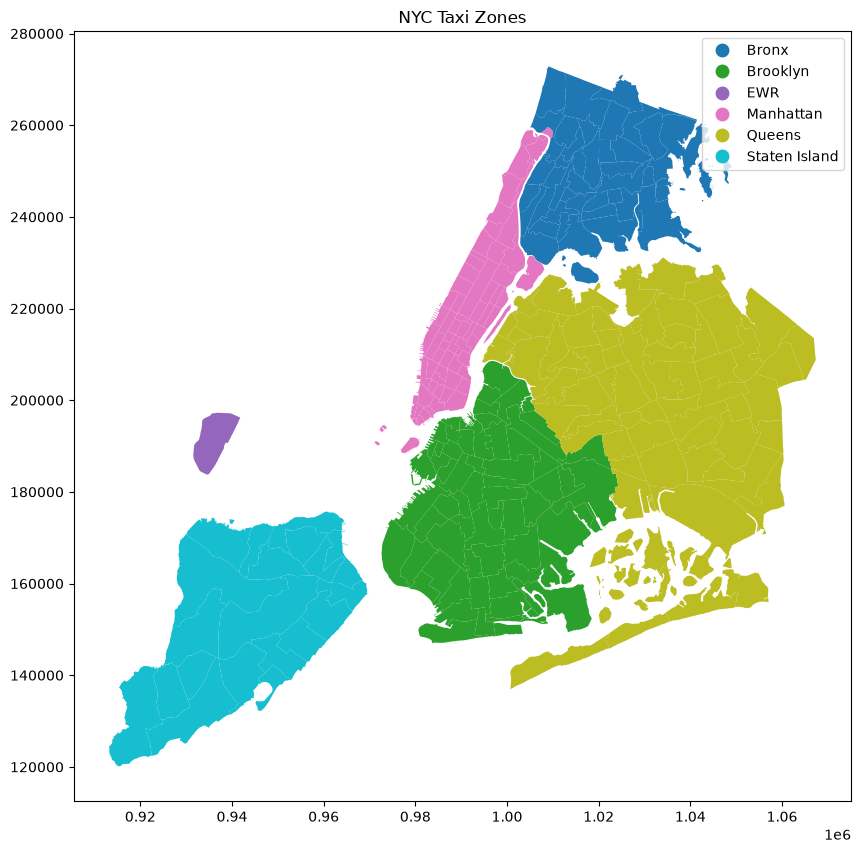

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

gdf = gpd.read_file("data/taxi_zones/taxi_zones/taxi_zones.shp")

gdf.plot(
    column="borough",
    legend=True,
    figsize=(12, 10)
)

plt.title("NYC Taxi Zones")
plt.show()

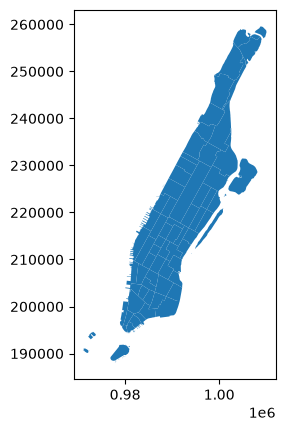

In [14]:
manhattan.plot()
plt.show()

In [ ]:
import requests
from pathlib import Path

base_url = "https://d37ci6vzurychx.cloudfront.net/trip-data"
output_dir = Path("data/yellow")
output_dir.mkdir(parents=True, exist_ok=True)

year = 2026

for month in range(1, 13):
    filename = f"yellow_tripdata_{year}-{month:02d}.parquet"
    url = f"{base_url}/{filename}"
    output_path = output_dir / filename

    print(f"Téléchargement de {filename}...")

    response = requests.get(url)
    response.raise_for_status()

    output_path.write_bytes(response.content)

In [ ]:
!pip install pyarrow
!pip install fastparquet

In [32]:
import pandas as pd

df = pd.read_parquet(
    "data/yellow/yellow_tripdata_2025-01.parquet",
    engine="fastparquet"
)

df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [56]:
print("Shape :", df.shape)

print("\nColonnes :")
print(df.columns)

print("\nTypes :")
print(df.dtypes)

print("\nInfo :")
df.info()

Shape : (3475226, 21)

Colonnes :
Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee', 'trip_duration_minutes'],
      dtype='str')

Types :
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
ti

In [34]:
df.isna().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          540149
trip_distance                 0
RatecodeID               540149
store_and_fwd_flag       540149
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     540149
Airport_fee              540149
cbd_congestion_fee            0
dtype: int64

In [37]:
(df.isna().sum() / len(df) * 100).round(2)

VendorID                  0.00
tpep_pickup_datetime      0.00
tpep_dropoff_datetime     0.00
passenger_count          15.54
trip_distance             0.00
RatecodeID               15.54
store_and_fwd_flag       15.54
PULocationID              0.00
DOLocationID              0.00
payment_type              0.00
fare_amount               0.00
extra                     0.00
mta_tax                   0.00
tip_amount                0.00
tolls_amount              0.00
improvement_surcharge     0.00
total_amount              0.00
congestion_surcharge     15.54
Airport_fee              15.54
cbd_congestion_fee        0.00
dtype: float64

In [38]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,3.475226e+06,3475226,3475226,2.935077e+06,3.475226e+06,2.935077e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,2.935077e+06,2.935077e+06,3.475226e+06
mean,1.785428e+00,2025-01-17 11:02:55.910964,2025-01-17 11:17:56.997901,1.297859e+00,5.855126e+00,2.482535e+00,1.651916e+02,1.641252e+02,1.036623e+00,1.708180e+01,1.317737e+00,4.780991e-01,2.959813e+00,4.493081e-01,9.547946e-01,2.561129e+01,2.225237e+00,1.239111e-01,4.834093e-01
min,1.000000e+00,2024-12-31 20:47:55,2024-12-18 07:52:40,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-9.000000e+02,-7.500000e+00,-5.000000e-01,-8.600000e+01,-1.269400e+02,-1.000000e+00,-9.010000e+02,-2.500000e+00,-1.750000e+00,-7.500000e-01
25%,2.000000e+00,2025-01-10 07:59:01,2025-01-10 08:15:29.500000,1.000000e+00,9.800000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.520000e+01,2.500000e+00,0.000000e+00,0.000000e+00
50%,2.000000e+00,2025-01-17 15:41:33,2025-01-17 15:59:34,1.000000e+00,1.670000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.211000e+01,0.000000e+00,5.000000e-01,2.450000e+00,0.000000e+00,1.000000e+00,1.995000e+01,2.500000e+00,0.000000e+00,7.500000e-01
75%,2.000000e+00,2025-01-24 19:34:06,2025-01-24 19:48:31,1.000000e+00,3.100000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.950000e+01,2.500000e+00,5.000000e-01,3.930000e+00,0.000000e+00,1.000000e+00,2.778000e+01,2.500000e+00,0.000000e+00,7.500000e-01
max,7.000000e+00,2025-02-01 00:00:44,2025-02-01 23:44:11,9.000000e+00,2.764236e+05,9.900000e+01,2.650000e+02,2.650000e+02,5.000000e+00,8.633721e+05,1.500000e+01,1.050000e+01,4.000000e+02,1.709400e+02,1.000000e+00,8.633804e+05,2.500000e+00,6.750000e+00,7.500000e-01
std,4.263282e-01,NaN,NaN,7.507503e-01,5.646016e+02,1.163277e+01,6.452948e+01,6.940169e+01,7.013334e-01,4.634729e+02,1.861509e+00,1.374623e-01,3.779681e+00,2.002582e+00,2.781938e-01,4.636585e+02,9.039932e-01,4.725090e-01,3.619307e-01


In [51]:
print("Total des trajets nulles :",(df["trip_distance"] == 0).sum())

print("Total des trajets très élévés :",(df["trip_distance"] > 1000).sum())

print("Total des montants de trajets négatifs :",(df["fare_amount"] < 0).sum())

print((df["total_amount"] < 0).sum())

Total des trajets nulles : 90893
Total des trajets très élévés : 116
Total des montants de trajets négatifs : 144118
63037


In [52]:
(
    df["tpep_dropoff_datetime"]
    < df["tpep_pickup_datetime"]
).sum()

np.int64(124)

In [53]:
df["trip_duration_minutes"] = (
    df["tpep_dropoff_datetime"]
    - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [ ]:
df["trip_duration_minutes"].describe().

count    3.475226e+06
mean     1.501812e+01
std      3.871358e+01
min     -5.147232e+04
25%      7.283333e+00
50%      1.170000e+01
75%      1.833333e+01
max      5.626317e+03
Name: trip_duration_minutes, dtype: float64

In [55]:
(df["trip_duration_minutes"] <= 0).sum()

np.int64(2051)

In [57]:
invalid_dates = (
    df["tpep_dropoff_datetime"]
    <= df["tpep_pickup_datetime"]
)

invalid_dates.sum()

np.int64(2051)

In [58]:
df["trip_duration_minutes"] = (
    df["tpep_dropoff_datetime"]
    - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [59]:
df["trip_duration_minutes"].describe()

count    3.475226e+06
mean     1.501812e+01
std      3.871358e+01
min     -5.147232e+04
25%      7.283333e+00
50%      1.170000e+01
75%      1.833333e+01
max      5.626317e+03
Name: trip_duration_minutes, dtype: float64

In [60]:
(df["trip_duration_minutes"] <= 0).sum()

np.int64(2051)

In [61]:
print("Distance = 0 :", (df["trip_distance"] == 0).sum())
print("Distance > 1000 :", (df["trip_distance"] > 1000).sum())
print("Fare négatif :", (df["fare_amount"] < 0).sum())
print("Total négatif :", (df["total_amount"] < 0).sum())

Distance = 0 : 90893
Distance > 1000 : 116
Fare négatif : 144118
Total négatif : 63037


In [62]:
n = len(df)

print(
    "Distance = 0 :",
    round((df["trip_distance"] == 0).sum() / n * 100, 2),
    "%"
)

print(
    "Distance > 1000 :",
    round((df["trip_distance"] > 1000).sum() / n * 100, 4),
    "%"
)

print(
    "Fare négatif :",
    round((df["fare_amount"] < 0).sum() / n * 100, 2),
    "%"
)

print(
    "Total négatif :",
    round((df["total_amount"] < 0).sum() / n * 100, 2),
    "%"
)

Distance = 0 : 2.62 %
Distance > 1000 : 0.0033 %
Fare négatif : 4.15 %
Total négatif : 1.81 %
